In [5]:
#%pip install -U sentence-transformers scikit-learn

In [6]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

import torch
import json 

from pathlib import Path 
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import MultiLabelBinarizer
from sklearn.metrics.pairwise import cosine_similarity

In [7]:
PROCESSED_PATH = Path("../data/processed")
EMBEDDINGS_PATH = Path("../data/embeddings")

EMBEDDINGS_PATH.mkdir(parents=True, exist_ok=True)

## Wczytanie datasetu przygotowanego w 02_Preprocessing.ipynb

In [8]:
df = pd.read_parquet(PROCESSED_PATH / "movies_processed.parquet")

print(df.shape)
display(df.head())

(45430, 20)


,id,title,overview,genres,runtime,vote_average,vote_count,release_date,original_language,popularity,imdb_id,release_year,genres_list,keywords_list,directors,top_cast,keywords_text,genres_text,embedding_text,runtime_category
0,862,Toy Story,"Led by Woody, Andy's toys live happily in his ...","[{'id': 16, 'name': 'Animation'}, {'id': 35, '...",81.0,7.7,5415.0,1995-10-30,en,21.946943,tt0114709,1995.0,"[Animation, Comedy, Family]","[jealousy, toy, boy, friendship, friends, riva...",[John Lasseter],"[Tom Hanks, Tim Allen, Don Rickles, Jim Varney...","jealousy, toy, boy, friendship, friends, rival...","Animation, Comedy, Family","Plot: Led by Woody, Andy's toys live happily i...",short
1,8844,Jumanji,When siblings Judy and Peter discover an encha...,"[{'id': 12, 'name': 'Adventure'}, {'id': 14, '...",104.0,6.9,2413.0,1995-12-15,en,17.015539,tt0113497,1995.0,"[Adventure, Fantasy, Family]","[board game, disappearance, based on children'...",[Joe Johnston],"[Robin Williams, Jonathan Hyde, Kirsten Dunst,...","board game, disappearance, based on children's...","Adventure, Fantasy, Family",Plot: When siblings Judy and Peter discover an...,medium
2,15602,Grumpier Old Men,A family wedding reignites the ancient feud be...,"[{'id': 10749, 'name': 'Romance'}, {'id': 35, ...",101.0,6.5,92.0,1995-12-22,en,11.712900,tt0113228,1995.0,"[Romance, Comedy]","[fishing, best friend, duringcreditsstinger, o...",[Howard Deutch],"[Walter Matthau, Jack Lemmon, Ann-Margret, Sop...","fishing, best friend, duringcreditsstinger, ol...","Romance, Comedy",Plot: A family wedding reignites the ancient f...,medium
3,31357,Waiting to Exhale,"Cheated on, mistreated and stepped on, the wom...","[{'id': 35, 'name': 'Comedy'}, {'id': 18, 'nam...",127.0,6.1,34.0,1995-12-22,en,3.859495,tt0114885,1995.0,"[Comedy, Drama, Romance]","[based on novel, interracial relationship, sin...",[Forest Whitaker],"[Whitney Houston, Angela Bassett, Loretta Devi...","based on novel, interracial relationship, sing...","Comedy, Drama, Romance","Plot: Cheated on, mistreated and stepped on, t...",long
4,11862,Father of the Bride Part II,Just when George Banks has recovered from his ...,"[{'id': 35, 'name': 'Comedy'}]",106.0,5.7,173.0,1995-02-10,en,8.387519,tt0113041,1995.0,[Comedy],"[baby, midlife crisis, confidence, aging, daug...",[Charles Shyer],"[Steve Martin, Diane Keaton, Martin Short, Kim...","baby, midlife crisis, confidence, aging, daugh...",Comedy,Plot: Just when George Banks has recovered fro...,medium


In [9]:
display(df[
    [
        "id", "title", "embedding_text", "genres_list"
    ]
].head())

,id,title,embedding_text,genres_list
0,862,Toy Story,"Plot: Led by Woody, Andy's toys live happily i...","[Animation, Comedy, Family]"
1,8844,Jumanji,Plot: When siblings Judy and Peter discover an...,"[Adventure, Fantasy, Family]"
2,15602,Grumpier Old Men,Plot: A family wedding reignites the ancient f...,"[Romance, Comedy]"
3,31357,Waiting to Exhale,"Plot: Cheated on, mistreated and stepped on, t...","[Comedy, Drama, Romance]"
4,11862,Father of the Bride Part II,Plot: Just when George Banks has recovered fro...,[Comedy]


In [ ]:
device = "cuda" if torch.cuda.is_available() else "cpu"
print("Device:", device)

model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device=device)

print("Embeddings dimensions: ", model.get_embedding_dimension())
print("Max sequence length: ", model.max_seq_length)

Device: cpu


Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Embeddings dimensions:  384
Max sequence length:  256


C:\Users\Patrycja\AppData\Local\Temp\ipykernel_6172\3881499816.py:6: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  print("Embeddings dimensions: ", model.get_sentence_embedding_dimension())


## Przygotowanie tekstów

In [11]:
df["embedding_text"] = (
    df["embedding_text"]
    .fillna("")
    .astype(str)
    .str.strip()
)

texts = df["embedding_text"].tolist()

print("Number of movies:", len(texts))
print("Empty texts:", sum(not text for text in texts))

Number of movies: 45430
Empty texts: 754


In [12]:
token_lengths = [
    len(tokens)
    for tokens in model.tokenizer(
        texts,
        add_special_tokens=True,
        truncation=False
    )["input_ids"]
]

print("Maximum tokens:", max(token_lengths))
print("Median tokens:", np.median(token_lengths))

print("Texts exceeding model limit:",
    sum(length > model.max_seq_length for length in token_lengths)
)

[transformers] Token indices sequence length is longer than the specified maximum sequence length for this model (273 > 256). Running this sequence through the model will result in indexing errors


Maximum tokens: 651
Median tokens: 76.0
Texts exceeding model limit: 65


## Generowanie embeddingów

In [ ]:
#żeby nie generować embeddingów dla filmów bez opisu i słów kluczowych
valid_mask = df["embedding_text"].str.len() > 0
valid_indices = np.flatnonzero(valid_mask.to_numpy())

valid_texts = df.loc[valid_mask, "embedding_text"].tolist()

print("Movies with text:", len(valid_texts))

Movies with text: 44676


In [14]:
text_embeddings_valid = model.encode(
    valid_texts,
    batch_size=64 if device == "cuda" else 32,
    show_progress_bar=True,
    convert_to_numpy=True,
    normalize_embeddings=True
)

print(text_embeddings_valid.shape)

Batches:   0%|          | 0/1397 [00:00<?, ?it/s]

(44676, 384)


In [15]:
embedding_dim = model.get_sentence_embedding_dimension()

#macierz, gdzie każdy wiersz odpowiada jednemu filmowi
text_embeddings = np.zeros(
    (len(df), embedding_dim),
    dtype=np.float32
)

text_embeddings[valid_indices] = text_embeddings_valid

C:\Users\Patrycja\AppData\Local\Temp\ipykernel_6172\1043902010.py:1: FutureWarning: The `get_sentence_embedding_dimension` method has been renamed to `get_embedding_dimension`.
  embedding_dim = model.get_sentence_embedding_dimension()


In [16]:
print("Shape:", text_embeddings.shape)
print("Data type:", text_embeddings.dtype)
print("NaN values:", np.isnan(text_embeddings).sum())

Shape: (45430, 384)
Data type: float32
NaN values: 0


### Wizualizacja norm wektorów

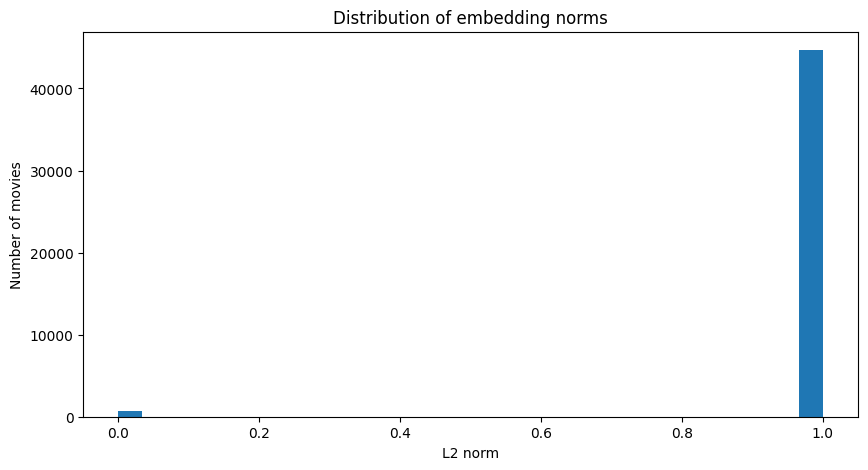

In [17]:
norms = np.linalg.norm(text_embeddings, axis=1)

plt.figure(figsize=(10, 5))
plt.hist(norms, bins=30)

plt.title("Distribution of embedding norms")
plt.xlabel("L2 norm")
plt.ylabel("Number of movies")

plt.show()

## Multi-Hot Encoding gatunków

In [20]:
mlb = MultiLabelBinarizer()

genres_embeddings = mlb.fit_transform(df["genres_list"]).astype("float32")

print("Genres shape:", genres_embeddings.shape)
print("Genres:", mlb.classes_)

Genres shape: (45430, 20)
Genres: ['Action' 'Adventure' 'Animation' 'Comedy' 'Crime' 'Documentary' 'Drama'
 'Family' 'Fantasy' 'Foreign' 'History' 'Horror' 'Music' 'Mystery'
 'Romance' 'Science Fiction' 'TV Movie' 'Thriller' 'War' 'Western']


## Test podobieństwa filmów

In [21]:
def find_similar_movies(title, top_n=10):
    matches = df[df["title"].str.lower() == title.lower()]

    if matches.empty:
        print("Movie not found")
        return

    idx = matches.index[0]

    if not valid_mask.iloc[idx]:
        print("This movie has no text embedding")
        return

    similarity = text_embeddings @ text_embeddings[idx]

    similarity[~valid_mask.to_numpy()] = -np.inf
    similarity[idx] = -np.inf

    similar_indices = np.argsort(similarity)[::-1][:top_n]

    results = df.iloc[similar_indices][["title", "genres_list", "vote_average"]].copy()

    results["similarity"] = similarity[similar_indices]

    return results

In [22]:
df = df.reset_index(drop=True)
display(find_similar_movies("Interstellar"))

,title,genres_list,vote_average,similarity
37011,Time Runner,[Science Fiction],4.6,0.622721
4725,Destiny in Space,[Documentary],7.0,0.618872
3235,Mission to Mars,[Science Fiction],5.7,0.608070
18987,Prometheus,"[Science Fiction, Adventure, Mystery]",6.3,0.601841
32478,Journey to Space,[Documentary],6.3,0.599763
9410,Far Side of the Moon,"[Drama, Comedy]",7.4,0.583147
16328,On the Silver Globe,"[Science Fiction, Adventure, Fantasy]",8.5,0.582497
3855,Red Planet,"[Thriller, Action, Science Fiction]",5.4,0.564853
13882,The Inhabited Island,"[Action, Fantasy, Science Fiction, Thriller]",5.4,0.556963
27082,The Day Mars Invaded Earth,[Science Fiction],5.4,0.556857


In [28]:
np.save(EMBEDDINGS_PATH / "text_embeddings.npy", text_embeddings)
np.save(EMBEDDINGS_PATH / "genres_embeddings.npy", genres_embeddings)
np.save(EMBEDDINGS_PATH / "movie_ids.npy", df["id"].to_numpy())
np.save(EMBEDDINGS_PATH/ "genre_names.npy", mlb.classes_.astype(str))